# Week 10 Report: Four-Format Data Recovery and Validation
**DSA4153 Programming for Data Science · Group 2**
Gillian Maxine Estilloso · Kaycelyn Tigas · Giana Elisha Tuplano · Hans Adrian Laudato

This notebook reports what our program did, as well as the analysis of its results. It **imports the program's own code from `src/`** (readers, validation, reconciliation, analysis, matrix and export modules) and uses it to re-check the generated files in `outputs/`.

**Contents:** 1 Setup · 2 Recovery counts · 3 Quarantine · 4 Duplicates · 5 Agreement across formats · 6 Canonical table checks · 7 pandas analysis · 8 NumPy matrix · 9 Export round trips · 10 Validation summary · 11 Interpretation and limits

## 1. Setup: import the program code and load the outputs

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, ".")          # run the notebook from the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)

# our program code
from src.common import load_config
from src.validation import validate_record
from src.reconcile import compare_tables, compare_all
from src.analysis import asia_selected_year, country_history
from src.matrix import build_population_matrix, index_to_baseline, index_by_loop, asia_total, matrix_to_frame
from src.export import read_export, apply_schema, roundtrip_check

config = load_config("config.json")
schema, atol = config["schema"], config["tolerance"]["abs"]
year = config["reporting_year"]
OUT = Path(config["output_dir"])

canonical = apply_schema(pd.read_csv(OUT/"canonical.csv", keep_default_na=False), schema)
quarantine = pd.read_csv(OUT/"quarantine.csv", keep_default_na=False)
duplicates = pd.read_csv(OUT/"duplicate_log.csv")
checks = pd.read_csv(OUT/"validation.csv")
audit = pd.read_csv(OUT/"audit_log.csv")
print("reporting year:", year, "| tolerance:", atol, "| canonical rows:", len(canonical))

reporting year: 2007 | tolerance: 1e-08 | canonical rows: 1704


With `config.json`, which acts as the program’s central control panel. It lists the input files and their format settings, the column mappings, the schema and allowed values, the tolerance, the reporting year and the matrix choices. Because the analysis functions take the year as a parameter instead of fixing it in the code, changing `reporting_year` (for example from 2007 to 1997) and rerunning `python main.py --config config.json` regenerates the Asia analysis without editing any processing function. The 2007 control totals are only checked when the reporting year is 2007.

## 2. Recovery counts per input

This part contains the use of the following codes: `readers.py`, `pipeline.py`, `audit.py`. Each input holds **1,712 raw records**. The program parses the layout, maps columns, validates values *before* integer conversion, removes exact duplicates, checks for conflicting keys and sorts. The audit log records the row count at every step.

In [2]:
steps = audit[audit.source_file.str.startswith("country_records")]
flow = steps.pivot_table(index="source_file", columns="operation", values="rows_after", aggfunc="last")
flow = flow[["parse", "validate", "deduplicate", "sort"]]
flow.columns = ["raw (parsed)", "after validation", "after de-duplication", "canonical (sorted)"]
flow

,raw (parsed),after validation,after de-duplication,canonical (sorted)
source_file,,,,
country_records.csv,1712,1706,1704,1704
country_records.json,1712,1706,1704,1704
country_records.parquet,1712,1706,1704,1704
country_records.xlsx,1712,1706,1704,1704


In [3]:
recon = pd.DataFrame({
    "raw": flow["raw (parsed)"],
    "rejected": flow["raw (parsed)"] - flow["after validation"],
    "duplicates removed": flow["after validation"] - flow["after de-duplication"],
    "canonical": flow["canonical (sorted)"],
})
recon["raw = rejected + duplicates + canonical"] = recon.raw == recon.rejected + recon["duplicates removed"] + recon.canonical
total = recon[["raw","rejected","duplicates removed","canonical"]].sum()
display(recon)
print("Across all four inputs ->", int(total.rejected), "quarantined,", int(total["duplicates removed"]), "duplicate copies removed")

,raw,rejected,duplicates removed,canonical,raw = rejected + duplicates + canonical
source_file,,,,,
country_records.csv,1712,6,2,1704,True
country_records.json,1712,6,2,1704,True
country_records.parquet,1712,6,2,1704,True
country_records.xlsx,1712,6,2,1704,True


Across all four inputs -> 24 quarantined, 8 duplicate copies removed


**Reading:** every format reconciles exactly: `1,712 = 6 rejected + 2 duplicates + 1,704 canonical rows`. Across the four inputs that is **24 quarantined** records and **8 duplicate copies** removed, as the task expects. We did **not** concatenate the four files (that would give 6,816 rows); each format is recovered independently, compared, and then one shared canonical table is built.

## 3. Quarantine: which records were rejected, and why

In [4]:
quarantine["field"] = quarantine.reason.str.split(":").str[0]
by_field = quarantine.pivot_table(index="field", columns="source_file", values="source_record", aggfunc="count", fill_value=0)
by_field["total"] = by_field.sum(axis=1)
by_field

source_file,country_records.csv,country_records.json,country_records.parquet,country_records.xlsx,total
field,,,,,
country,1,1,1,1,4
gdpPercap,1,1,1,1,4
lifeExp,1,1,1,1,4
pop,2,2,2,2,8
year,1,1,1,1,4


In [5]:
# Independent re-check with our own validate_record(): every quarantined row must fail again.
order = schema["canonical_order"]
def still_rejected(row):
    clean, reason = validate_record({c: row[c] for c in order}, schema)
    return reason is not None
print("quarantined rows:", len(quarantine), "| rejected again by validate_record:", int(quarantine.apply(still_rejected, axis=1).sum()))
quarantine[["source_file","source_record","reason"]].head(6)

quarantined rows: 24 | rejected again by validate_record: 24


,source_file,source_record,reason
0,country_records.csv,77,pop: fractional value '100.5' where a whole nu...
1,country_records.csv,232,year: not a number 'not-a-year'
2,country_records.csv,377,lifeExp: 150.0 is greater than 120
3,country_records.csv,647,pop: -1 is not greater than 0
4,country_records.csv,973,gdpPercap: not a number 'not-a-number'
5,country_records.csv,1176,country: missing or empty


**Code used:** `validation.py` (Kaycelyn). `map_columns` renames the source columns and raises a `SchemaError` if a required column is missing. `validate_dataframe` then passes every record to `validate_record`, which checks each of the six canonical fields against the schema in `config.json` **before any integer conversion**:

- text fields must not be empty after trimming, and `continent` must be in the allowed set;
- numbers are parsed by `parse_float` and `parse_integer`, which reject non-numeric text, non-finite values and fractional values where a whole number is required;
- `year` must be in `allowed_years`;
- `lifeExp`, `pop` and `gdpPercap` must satisfy the `min_exclusive` and `max_inclusive` rules (for example `lifeExp` must be above 0 and at most 120).

A valid record is stored by `ValidationResult.add_accepted`. An invalid one is stored by `add_rejected` with its reason, its original text values and its one-based `source_record`. Type conversion happens only afterwards, in `to_frame`. The pipeline writes the rejected records to `quarantine.csv`, and `validation.csv` records the counts (6 rejected per file, 24 in total).

**Reading:** each file contains the same six defective records: a fractional population (`100.5`), a non-numeric year (`not-a-year`), an impossible life expectancy (`150`, above the limit of 120), a negative population (`-1`), a non-numeric GDP (`not-a-number`) and an empty country. Each is rejected with a clear reason and keeps its original text and position. The same defects sit at different positions in each file because the files are in different orders, so validity is decided from the values, and the position is only recorded so a rejected record can be traced back.

## 4. Exact duplicates

In [6]:
duplicates.groupby("source_file").size().to_frame("copies removed").join(
    duplicates.groupby("source_file").apply(lambda d: ", ".join(sorted(set(d.country + " " + d.year.astype(str)))), include_groups=False).rename("records duplicated"))

,copies removed,records duplicated
source_file,,
country_records.csv,2,"Afghanistan 1977, Bangladesh 1972"
country_records.json,2,"Afghanistan 1977, Bangladesh 1972"
country_records.parquet,2,"Afghanistan 1977, Bangladesh 1972"
country_records.xlsx,2,"Afghanistan 1977, Bangladesh 1972"


**Code used:** `reconcile.py` (Giana). `remove_exact_duplicates` goes through the valid records in order and builds a signature from the six canonical fields. The first time a signature appears the record is kept. Any later record with the same signature is dropped and logged with its `source_record` and `duplicate_of_record` (the position of the copy it repeats). `check_conflicts` then looks for any `(country, year)` key that still appears more than once. Because exact copies are already gone, a repeated key can only mean two records that disagree, so it raises a `ConflictError` and stops the run instead of keeping the first row. `sort_canonical` finishes by sorting by country, then year.

**Reading:** two valid records (Bangladesh 1972 and Afghanistan 1977) appear twice in every file. They are identical in all six fields, so the second copy is removed and logged in `duplicate_log.csv`, giving 8 removed copies across the four files. `conflicting_key.csv` demonstrates the other case: two rows share a key but differ in another field, so the program stops.

## 5. Agreement across the four formats

In [7]:
agree = checks[checks.check.str.startswith("agreement")]
display(agree)
# Re-do the comparison here with our own compare_tables, on the four exported canonical files.
tables = {fmt: apply_schema(read_export(OUT/f, fmt, config["export_sheet"]), schema) for fmt, f in config["exports"].items()}
for name, diff in compare_all(tables, schema, atol).items():
    print(name, "vs csv ->", len(diff), "differences")

,check,expected,actual,tolerance,pass
22,agreement: country_records.xlsx vs country_rec...,0,0,1e-08,True
23,agreement: country_records.json vs country_rec...,0,0,1e-08,True
24,agreement: country_records.parquet vs country_...,0,0,1e-08,True


xlsx vs csv -> 0 differences
json vs csv -> 0 differences
parquet vs csv -> 0 differences


**Code used:** `reconcile.py` (Giana). `compare_all` compares the table from each format with the first one (the CSV) by calling `compare_tables`. That function:

- confirms both tables have the canonical columns and no repeated keys;
- confirms the two sets of `(country, year)` keys are identical;
- indexes both tables by key and sorts them, so row order does not matter;
- compares missingness, then `float64` columns with `np.isclose` using an absolute tolerance of 1e-8 and relative tolerance of 0, and text and integer columns for exact equality.

In `pipeline.py`, each result becomes a row in `validation.csv`, and any difference raises an `AgreementError`. The shared canonical table is created only after every comparison passes.

**Reading:** all three comparisons (Excel, JSON and Parquet against CSV) show zero differences, so the four recovered tables hold the same observations. Comparing by key, not by row position, is what lets this work even though each file lists the records in a different order.

## 6. Canonical table checks

In [8]:
print(canonical.shape, "| countries:", canonical.country.nunique(), "| years:", [int(y) for y in sorted(canonical.year.unique())])
print("repeated keys:", int(canonical.duplicated(["country","year"]).sum()), "| missing values:", int(canonical.isna().sum().sum()))
print(dict(canonical.dtypes.astype(str)))
canonical.groupby("continent").agg(countries=("country","nunique"), rows=("country","size")).sort_values("rows", ascending=False)

(1704, 6) | countries: 142 | years: [1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, 2002, 2007]
repeated keys: 0 | missing values: 0
{'country': 'string', 'continent': 'string', 'year': 'int64', 'lifeExp': 'float64', 'pop': 'int64', 'gdpPercap': 'float64'}


,countries,rows
continent,,
Africa,52,624
Asia,33,396
Europe,30,360
Americas,25,300
Oceania,2,24


**Code used:** `domain_checks` in `pipeline.py` (Hans), which uses the schema in `config.json` (Gillian). It runs on the shared canonical table and checks, using sets where membership matters: repeated `(country, year)` keys, the number of distinct countries (142), years outside the `allowed_years` set, continents outside the `allowed_continents` set, missing values, empty text values, the column order, and that the dtypes match the schema. `apply_schema` in `export.py` restores the declared types when the table is reloaded.

**Reading:** the table has 1,704 rows, which is 142 countries × 12 years (1952-2007, in five-year steps). Keys are unique, nothing is missing, and the types are `int64` for year and pop and `float64` for lifeExp and gdpPercap. Units follow the manifest: years, persons and inflation-adjusted US dollars. The data describes 1952-2007, not current conditions.

## 7. pandas analysis

### 7.1 Asia in the reporting year
Selected with `.loc`, with population in millions and a descending life-expectancy rank using `method="min"`.

In [9]:
asia = asia_selected_year(canonical, year, config["analysis"]["continent"])
saved = pd.read_csv(OUT/"asia_selected_year.csv")
print("rows:", len(asia), "| matches saved asia_selected_year.csv:", asia.reset_index(drop=True).equals(saved.astype(asia.dtypes.to_dict(), errors="ignore")) or np.allclose(asia[["lifeExp","pop_millions"]], saved[["lifeExp","pop_millions"]]))
asia[["lifeExp_rank","country","lifeExp","pop_millions","gdpPercap"]].head(8)

rows: 33 | matches saved asia_selected_year.csv: True


,lifeExp_rank,country,lifeExp,pop_millions,gdpPercap
0,1,Japan,82.603,127.467972,31656.06806
1,2,"Hong Kong, China",82.208,6.980412,39724.97867
2,3,Israel,80.745,6.426679,25523.27710
3,4,Singapore,79.972,4.553009,47143.17964
4,5,"Korea, Rep.",78.623,49.044790,23348.13973
5,6,Taiwan,78.400,23.174294,28718.27684
6,7,Kuwait,77.588,2.505559,47306.98978
7,8,Oman,75.640,3.204897,22316.19287


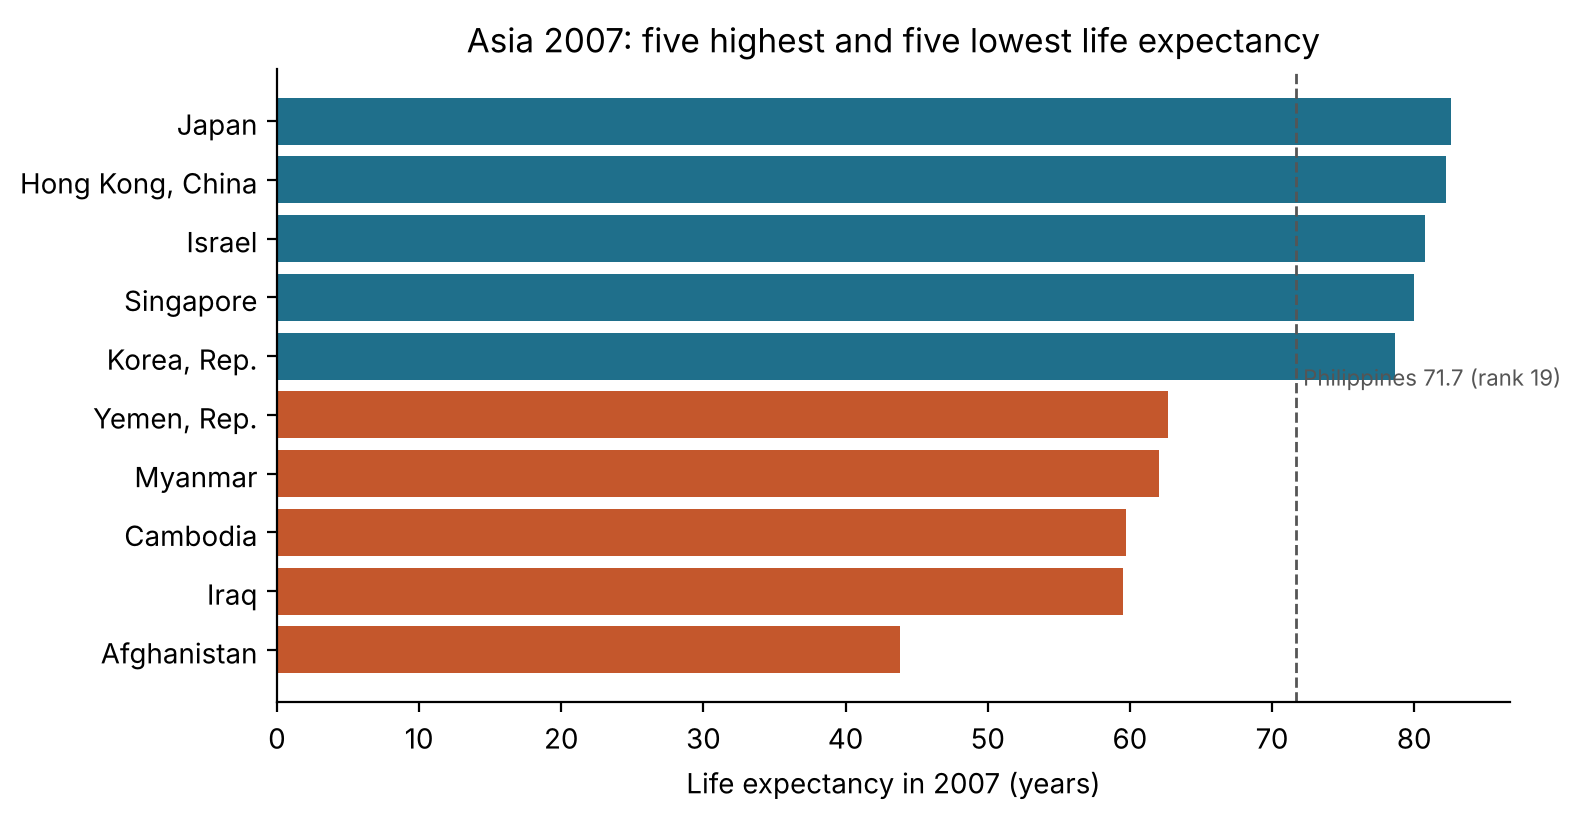

In [10]:
top, bottom = asia.head(5), asia.tail(5)
fig, ax = plt.subplots(figsize=(8, 4.2))
sel = pd.concat([top, bottom])
colors = ["#1f6f8b"]*5 + ["#c4572c"]*5
ax.barh(sel.country[::-1], sel.lifeExp[::-1], color=colors[::-1])
ph = asia[asia.country=="Philippines"].iloc[0]
ax.axvline(ph.lifeExp, color="#555", ls="--", lw=1); ax.text(ph.lifeExp+.5, 4.5, f"Philippines {ph.lifeExp:.1f} (rank {int(ph.lifeExp_rank)})", fontsize=8, color="#555")
ax.set_xlabel("Life expectancy in 2007 (years)"); ax.set_title("Asia 2007: five highest and five lowest life expectancy")
ax.spines[["top","right"]].set_visible(False); plt.tight_layout(); plt.show()

In [11]:
print("Asia total population:", f"{int(asia['pop'].sum()):,}", "| Philippines:", f"{int(ph['pop']):,}", f"({ph['pop']/asia['pop'].sum():.1%} of Asia)")
big = asia.sort_values("pop", ascending=False).head(2)
print("China + India share of Asia:", f"{big['pop'].sum()/asia['pop'].sum():.1%}")

Asia total population: 3,811,953,827 | Philippines: 91,077,287 (2.4% of Asia)
China + India share of Asia: 63.7%


**Code used:** `asia_selected_year` in `analysis.py` (Gillian). It builds a Boolean mask for the configured continent and year, selects rows with `.loc`, adds `pop_millions` (population divided by 1,000,000), and ranks life expectancy in descending order with `rank(method="min")`, so ties share the lowest rank. It sorts by rank, then country. `pipeline.py` passes in `reporting_year` and `config["analysis"]["continent"]`, and then checks the result against a NumPy mask.

**Reading:** Asia has 33 countries in 2007 with a total population of 3,811,953,827. Japan ranks first (82.6 years) and Afghanistan last (43.8). The Philippines ranks 19th at 71.7 years. China and India together are about 64% of Asia's population.

### 7.2 Philippines history

rows: 12


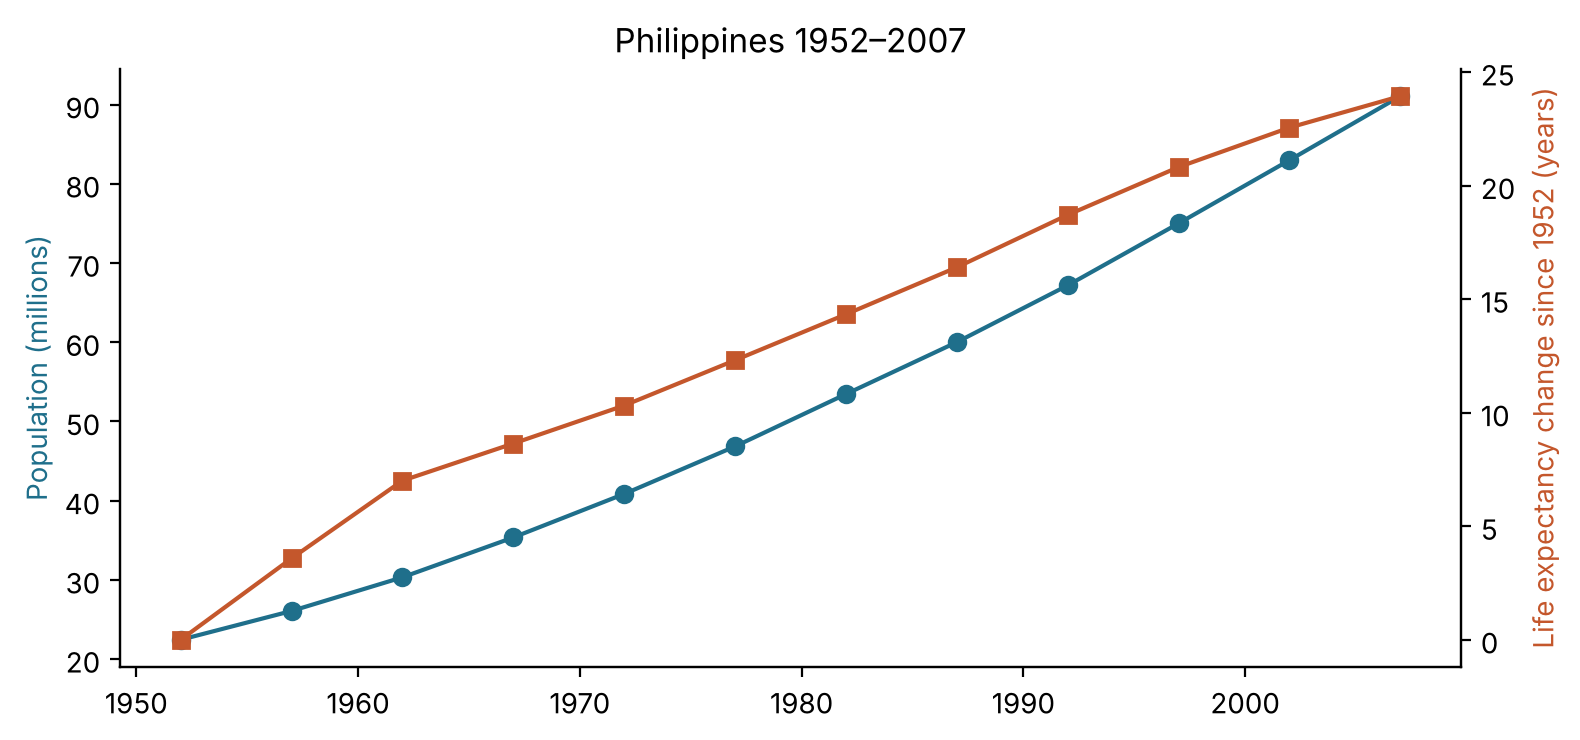

,year,pop_millions,lifeExp,lifeExp_change
0,1952,22.438691,47.752,0.000
1,1957,26.072194,51.334,3.582
2,1962,30.325264,54.757,7.005
3,1967,35.356600,56.393,8.641
4,1972,40.850141,58.065,10.313
5,1977,46.850962,60.060,12.308
6,1982,53.456774,62.082,14.330
7,1987,60.017788,64.151,16.399
8,1992,67.185766,66.458,18.706
9,1997,75.012988,68.564,20.812


In [12]:
hist = country_history(canonical, config["analysis"]["history_country"])
print("rows:", len(hist))
fig, ax1 = plt.subplots(figsize=(8, 3.8))
ax1.plot(hist.year, hist.pop_millions, color="#1f6f8b", marker="o"); ax1.set_ylabel("Population (millions)", color="#1f6f8b")
ax2 = ax1.twinx(); ax2.plot(hist.year, hist.lifeExp_change, color="#c4572c", marker="s"); ax2.set_ylabel("Life expectancy change since 1952 (years)", color="#c4572c")
ax1.set_title("Philippines 1952–2007"); ax1.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False); plt.tight_layout(); plt.show()
hist[["year","pop_millions","lifeExp","lifeExp_change"]]

**Code used:** `country_history` in `analysis.py` (Gillian). It selects one country's rows, sorts by year, raises a `ProcessingError` if none are found, adds `pop_millions`, and computes `lifeExp_change` by subtracting the first year's life expectancy (`iloc[0]`) from every row. The pipeline checks that there are 12 rows, that the 2007 population is 91,077,287, and that the first change is 0.

**Reading:** the Philippines grew from 22.4 million to 91.1 million people, about four times larger. Life expectancy rose by 23.9 years (47.8 to 71.7), at roughly 3.5 years per five-year step up to 1962 and about 2 years per step afterwards.

## 8. NumPy matrix and broadcasting

A 3 × 6 population matrix (Philippines, Indonesia, Thailand × 1982–2007) is built with Boolean selection. Each row is divided by its own 1982 value, using broadcasting, to give an index where 1982 = 100. A separately written loop verifies the result.

In [13]:
m = config["matrix"]
base_col = m["years"].index(m["baseline_year"])
matrix = build_population_matrix(canonical, m["countries"], m["years"])
info = index_to_baseline(matrix, base_col)
loop = index_by_loop(matrix, base_col)
print("matrix shape:", info["shape_matrix"], "| baseline shape (before broadcast):", info["shape_baseline"], "| index shape (after):", info["shape_index"])
print("max |broadcast - loop|:", float(abs(info["index"] - loop).max()))
index_df = matrix_to_frame(m["countries"], m["years"], info["index"]).round(1)
index_df

matrix shape: (3, 6) | baseline shape (before broadcast): (3, 1) | index shape (after): (3, 6)
max |broadcast - loop|: 0.0


,country,1982,1987,1992,1997,2002,2007
0,Philippines,100.0,112.3,125.7,140.3,155.3,170.4
1,Indonesia,100.0,110.4,120.5,130.0,137.6,145.8
2,Thailand,100.0,108.4,116.1,123.3,128.6,133.3


Boolean mask selects 33 Asian rows; NumPy sum = 3,811,953,827; pandas sum = 3,811,953,827


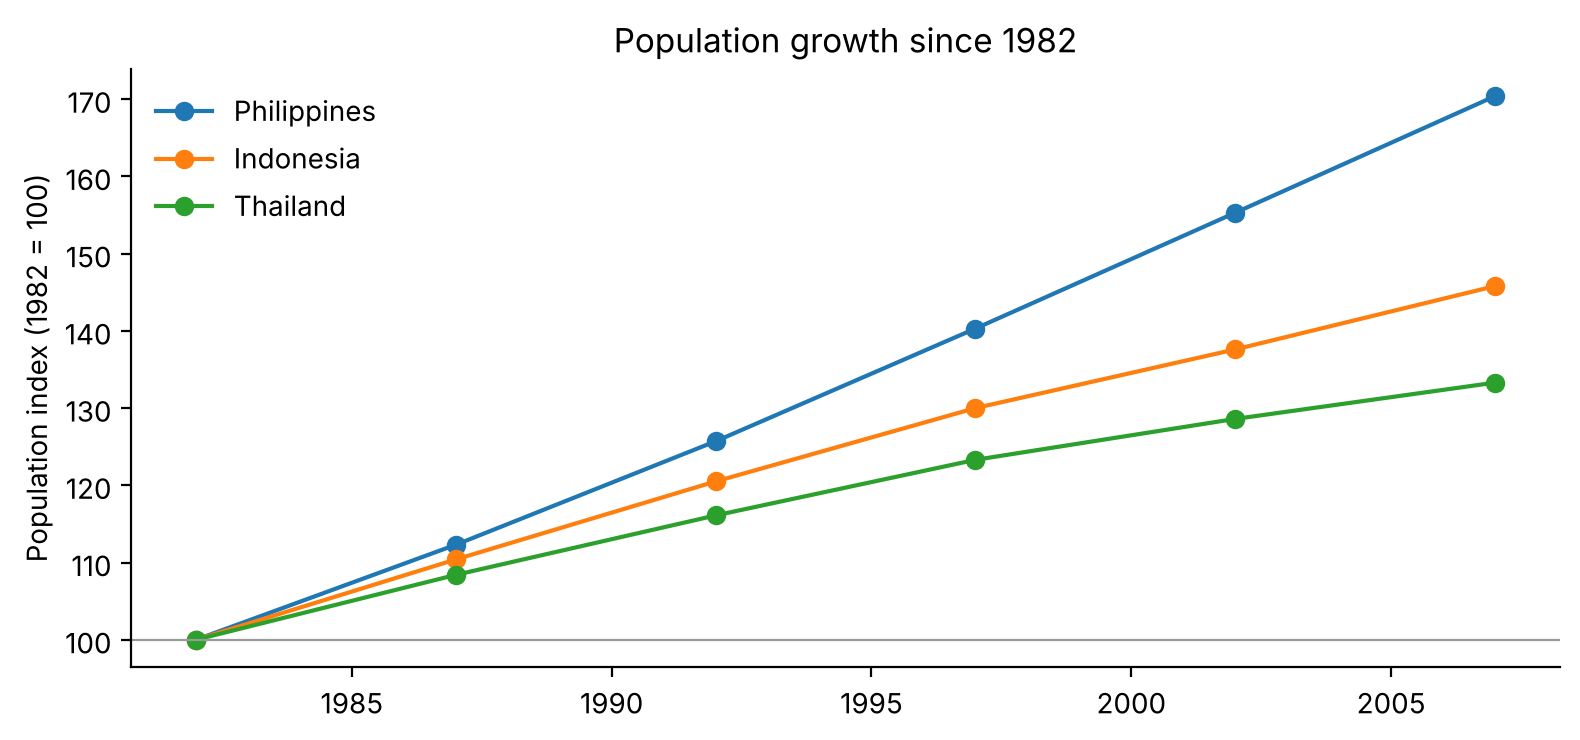

In [14]:
rows, total_np = asia_total(canonical, year, config["analysis"]["continent"])
print(f"Boolean mask selects {rows} Asian rows; NumPy sum = {total_np:,}; pandas sum = {int(asia['pop'].sum()):,}")
fig, ax = plt.subplots(figsize=(8, 3.8))
for _, r in index_df.iterrows():
    ax.plot(m["years"], r[[str(y) for y in m["years"]]].astype(float), marker="o", label=r["country"])
ax.axhline(100, color="#999", lw=.8); ax.set_ylabel("Population index (1982 = 100)"); ax.legend(frameon=False)
ax.set_title("Population growth since 1982"); ax.spines[["top","right"]].set_visible(False); plt.tight_layout(); plt.show()

**Code used:** `matrix.py` (Giana).
- `build_population_matrix` uses a Boolean mask on NumPy arrays (country and year) to fill a 3 × 6 integer matrix, and raises an error unless exactly one row matches each cell.
- `index_to_baseline` takes the 1982 column as a `(3, 1)` baseline and divides the `(3, 6)` matrix by it, so broadcasting gives a `(3, 6)` index with 1982 = 100.
- `index_by_loop` repeats the calculation with plain loops, as an independent check.
- `asia_total` uses a Boolean mask and a NumPy sum, independent of the pandas total.
- `matrix_to_frame` adds country labels and the six year columns for `population_index.csv`.

**Reading:** shapes are `(3, 6)` for the matrix, `(3, 1)` for the baseline and `(3, 6)` for the index. The broadcast result equals the loop result (maximum difference 0.0) and the 1982 column is exactly **100**. By 2007 the index is **170.4** for the Philippines, **145.8** for Indonesia and **133.3** for Thailand, so the Philippines grew fastest of the three. The NumPy Asia total equals the pandas total.

## 9. Export round trips

Each canonical export is reloaded, the declared schema is re-applied (CSV, Excel and JSON hand back plain text for strings, so a conversion is needed), and the result is compared with the pre-export table.

In [15]:
rows = []
for fmt, fname in config["exports"].items():
    problems, conversions = roundtrip_check(canonical, OUT/fname, fmt, schema, atol, config["export_sheet"])
    rows.append({"format": fmt, "file": fname, "differences": len(problems), "conversion needed": "; ".join(conversions) or "none"})
pd.DataFrame(rows)

,format,file,differences,conversion needed
0,csv,canonical.csv,0,country: str -> string; continent: str -> string
1,xlsx,canonical.xlsx,0,country: str -> string; continent: str -> string
2,json,canonical.json,0,country: str -> string; continent: str -> string
3,parquet,canonical.parquet,0,none


**Code used:** `export.py` (Hans). `write_export` writes the canonical table as CSV, Excel (sheet `observations`), JSON (records orientation) and Parquet, with no row index. `roundtrip_check` reloads each file with `read_export`, records any type conversion, applies the declared schema with `apply_schema` (which refuses missing, non-finite or fractional values), and compares the result with the original using `compare_tables` from `reconcile.py`. All of this runs in a staging folder, which `publish_staging` copies to `outputs/` only if every check passes.

**Reading:** all four exports reload with zero differences. The only conversion needed is the two text columns, which CSV, Excel and JSON return as plain `str` and which are restored to `string`. Parquet keeps its types, so it needs none. The test suite also checks that a deliberately altered export value fails this comparison.

## 10. Validation summary

In [16]:
checks["group"] = checks.check.str.extract(r"^(?:country_records\.\w+: )?(\w+)")[0].str.split().str[0]
summary = checks.assign(kind=np.where(checks.check.str.startswith("country_records"), "per-file reconciliation",
                np.where(checks.check.str.startswith("agreement"), "four-format agreement",
                np.where(checks.check.str.startswith("canonical"), "key/domain/schema",
                np.where(checks.check.str.startswith("numpy"), "NumPy",
                np.where(checks.check.str.startswith("round trip"), "export round trip", "analysis totals and controls")))))).groupby("kind")["pass"].agg(["count","sum"])
summary.columns = ["checks", "passed"]
display(summary)
print("All", len(checks), "checks passed:", bool(checks["pass"].all()))

,checks,passed
kind,,
NumPy,5,5
analysis totals and controls,11,11
export round trip,4,4
four-format agreement,3,3
key/domain/schema,8,8
per-file reconciliation,20,20


All 51 checks passed: True


**Code used:** `make_check` in `audit.py` (Hans) builds each row of `validation.csv`: numeric values pass if they are within the tolerance, other values must match exactly. `pipeline.py` collects the checks from every stage, and `write_checks` saves them. If any check fails, a `CheckFailedError` stops the run, the staging folder is discarded and a failed validation report is written. Each member's module supplies the checks for its own part.

**Reading:** all 51 checks pass: 20 per-file reconciliation checks, 3 four-format agreement checks, 8 key, domain and schema checks, 11 analysis and control checks, 5 NumPy checks and 4 export round trips. Together they show that the four formats recover the same dataset and that the exports can be trusted.

## 11. Interpretation and limits

**What the program established**
- Four very different files (CP1252 semicolon CSV with comment lines, a workbook with a Readme sheet, nested JSON and string-typed Parquet) were recovered into one identical table of **1,704 observations**.
- Bad data was handled by rule, not by position: 24 invalid records were quarantined with reasons, 8 exact duplicate copies were removed and logged, and a conflicting key would stop the run.
- Because the formats agree by key within tolerance, the canonical table can be trusted as *the* dataset rather than one of four possibly different versions.
- Results are checkable: pandas and NumPy give the same Asia total, broadcasting matches an independent loop, and every export reloads without differences.

**Findings from the data (1952–2007)**
- Asia 2007 totals 3.81 billion people; life expectancy ranges from 43.8 (Afghanistan) to 82.6 (Japan).
- The Philippines gained 23.9 years of life expectancy and quadrupled in population; its 2007 population index (1982 = 100) of 170.4 is higher than Indonesia's and Thailand's.

**Limits**
- The data is a historical snapshot (1952-2007), not current conditions.
- The six defects were added to the files for this exercise; they do not describe errors in the original Gapminder source.